In [ ]:
!pip install -q importlib_resources
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow_datasets as tfds

(pv_train, pv_val, pv_test), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)
leaf_classes = info.features["label"].names
print("Leaf classes:", len(leaf_classes))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.ZQBALM_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Leaf classes: 38


In [ ]:
!pip install -q importlib_resources
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import tensorflow_datasets as tfds

(pv_train, pv_val, pv_test), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)
leaf_classes = info.features["label"].names
print("Leaf classes:", len(leaf_classes))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.PJAOZ8_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Leaf classes: 38


In [ ]:
import numpy as np

# Photos of everyday things (not plants)
imagenette = tfds.load("imagenette/320px-v2", split="train+validation", as_supervised=True)
caltech, caltech_info = tfds.load(
    "caltech101", split="train+test", as_supervised=True, with_info=True
)

# Remove the Caltech categories that show plants
caltech_names = caltech_info.features["label"].names
plant_names = {"sunflower", "water_lilly", "lotus"}
plant_ids = tf.constant(
    [i for i, n in enumerate(caltech_names) if n in plant_names], dtype=tf.int64
)
print("Removing:", [caltech_names[i] for i in plant_ids.numpy()])
caltech = caltech.filter(lambda image, label: tf.reduce_all(tf.not_equal(label, plant_ids)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.ERMUGW_3.0.2/caltech101-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.ERMUGW_3.0.2/caltech101-test.tfrecord-[0-9][0-9][0-9…

Dataset caltech101 downloaded and prepared to /root/tensorflow_datasets/caltech101/3.0.2. Subsequent calls will reuse this data.
Removing: ['lotus', 'sunflower', 'water_lilly']


In [ ]:
def collect(dataset, n, seed):
    images = []
    for image, _ in dataset.shuffle(2000, seed=seed).take(n):
        images.append(tf.image.resize(image, (224, 224)).numpy().astype("uint8"))
    return np.stack(images)

neg_images = np.concatenate([collect(imagenette, 3000, 1), collect(caltech, 3000, 2)])

# Mix the two sources together
rng = np.random.default_rng(42)
neg_images = neg_images[rng.permutation(len(neg_images))]

NOT_LEAF = len(leaf_classes)   # the new class gets label number 38
neg_labels = np.full(len(neg_images), NOT_LEAF, dtype="int64")

print("Not-a-leaf images:", neg_images.shape)

Not-a-leaf images: (6000, 224, 224, 3)


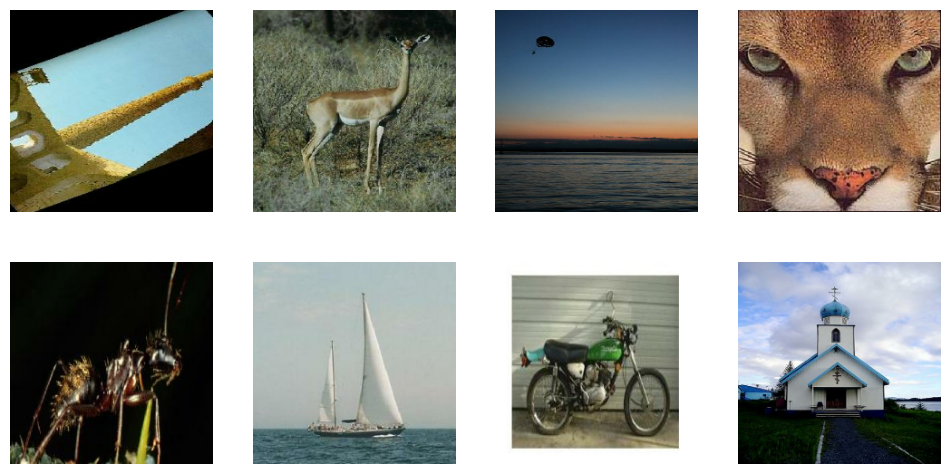

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(neg_images[i])
    plt.axis("off")
plt.show()

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def prepare(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return tf.cast(image, tf.float32), label


# Split the not-a-leaf photos: 80% training, 10% validation, 10% test
n = len(neg_images)
n_train, n_val = int(n * 0.8), int(n * 0.1)

neg_train = tf.data.Dataset.from_tensor_slices((neg_images[:n_train], neg_labels[:n_train]))
neg_val = tf.data.Dataset.from_tensor_slices(
    (neg_images[n_train:n_train + n_val], neg_labels[n_train:n_train + n_val])
)
neg_test = tf.data.Dataset.from_tensor_slices(
    (neg_images[n_train + n_val:], neg_labels[n_train + n_val:])
)

# Training: mix leaf and not-a-leaf photos, about 90% / 10%
train_ds = tf.data.Dataset.sample_from_datasets(
    [
        pv_train.map(prepare, num_parallel_calls=AUTOTUNE),
        neg_train.map(prepare, num_parallel_calls=AUTOTUNE),
    ],
    weights=[0.9, 0.1],
    seed=42,
)
train_ds = train_ds.shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE)


def batched(dataset):
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Validation: leaf and not-a-leaf photos together
val_ds = batched(
    pv_val.map(prepare, num_parallel_calls=AUTOTUNE).concatenate(neg_val.map(prepare))
)

# Two separate test sets, so we can judge each skill on its own
test_leaf = batched(pv_test.map(prepare, num_parallel_calls=AUTOTUNE))
test_neg = batched(neg_test.map(prepare))

# Quick check: a batch should contain a few labels equal to 38
for images, labels in train_ds.take(1):
    print("Images:", images.shape)
    print("Labels:", labels.numpy())

Images: (32, 224, 224, 3)
Labels: [38 38 31 37 37 24 14 24 16 19  8 37 27  9 22 38 32 25 28  4 16 15 32 37
 38 18 25 28 35 24 16  8]


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(leaf_classes) + 1   # 38 leaf classes + "not a leaf"

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=2, restore_best_weights=True
)

model.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=[early_stop])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/3
   1508/Unknown 108s 64ms/step - accuracy: 0.7322 - loss: 1.0054

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1508/1508 ━━━━━━━━━━━━━━━━━━━━ 121s 73ms/step - accuracy: 0.8347 - loss: 0.5756 - val_accuracy: 0.9085 - val_loss: 0.2964
Epoch 2/3
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 111s 73ms/step - accuracy: 0.9019 - loss: 0.3075 - val_accuracy: 0.9302 - val_loss: 0.2291
Epoch 3/3
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 142s 73ms/step - accuracy: 0.9110 - loss: 0.2705 - val_accuracy: 0.9237 - val_loss: 0.2291


In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[early_stop])

Epoch 1/5
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 149s 92ms/step - accuracy: 0.8349 - loss: 0.6626 - val_accuracy: 0.9328 - val_loss: 0.2050
Epoch 2/5
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 140s 92ms/step - accuracy: 0.9198 - loss: 0.2534 - val_accuracy: 0.9450 - val_loss: 0.1696
Epoch 3/5
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 141s 91ms/step - accuracy: 0.9341 - loss: 0.2060 - val_accuracy: 0.9534 - val_loss: 0.1463
Epoch 4/5
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 140s 92ms/step - accuracy: 0.9434 - loss: 0.1693 - val_accuracy: 0.9569 - val_loss: 0.1315
Epoch 5/5
1508/1508 ━━━━━━━━━━━━━━━━━━━━ 142s 92ms/step - accuracy: 0.9486 - loss: 0.1549 - val_accuracy: 0.9617 - val_loss: 0.1229


In [ ]:
_, leaf_acc = model.evaluate(test_leaf, verbose=0)
_, neg_acc = model.evaluate(test_neg, verbose=0)

print(f"Leaf photos classified correctly: {leaf_acc:.2%}   (the current model scored 95.99%)")
print(f"Not-a-leaf photos recognised:     {neg_acc:.2%}")

Leaf photos classified correctly: 95.56%   (the current model scored 95.99%)
Not-a-leaf photos recognised:     100.00%


In [ ]:
from google.colab import files
from PIL import Image
import io

class_names_v2 = leaf_classes + ["Not_a_leaf"]

uploaded = files.upload()

for name, data in uploaded.items():
    image = Image.open(io.BytesIO(data)).convert("RGB").resize((224, 224), Image.BILINEAR)
    batch = np.expand_dims(np.array(image, dtype="float32"), axis=0)
    probs = model.predict(batch, verbose=0)[0]
    top3 = np.argsort(probs)[::-1][:3]
    print(name)
    for i in top3:
        print(f"    {class_names_v2[i]}: {probs[i]:.1%}")

Saving potato H.jpg to potato H.jpg
Saving bellpepper.jpg to bellpepper.jpg
Saving human face.jpg to human face.jpg
Saving tiger.jpg to tiger.jpg
Saving rabbit.jpg to rabbit.jpg
Saving table.jpg to table.jpg
Saving Leaf 3.jpg to Leaf 3.jpg
Saving Leaf 2.jpg to Leaf 2.jpg
Saving Leaf 1.jpg to Leaf 1.jpg
Saving soybean.jpg to soybean.jpg
Saving orange leaf.jpg to orange leaf.jpg
potato H.jpg
    Grape___Black_rot: 59.8%
    Potato___Late_blight: 17.4%
    Not_a_leaf: 6.6%
bellpepper.jpg
    Pepper,_bell___healthy: 97.8%
    Soybean___healthy: 1.7%
    Pepper,_bell___Bacterial_spot: 0.5%
human face.jpg
    Not_a_leaf: 100.0%
    Corn___Northern_Leaf_Blight: 0.0%
    Corn___Cercospora_leaf_spot Gray_leaf_spot: 0.0%
tiger.jpg
    Not_a_leaf: 100.0%
    Tomato___Late_blight: 0.0%
    Corn___Northern_Leaf_Blight: 0.0%
rabbit.jpg
    Not_a_leaf: 98.8%
    Soybean___healthy: 0.2%
    Corn___Northern_Leaf_Blight: 0.2%
table.jpg
    Not_a_leaf: 100.0%
    Tomato___Spider_mites Two-spotted_spider_

In [ ]:
import json

model.save_weights("plant_model_v2.weights.h5")

with open("class_names_v2.json", "w") as f:
    json.dump(class_names_v2, f)

files.download("plant_model_v2.weights.h5")
files.download("class_names_v2.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>